# PaddleOCR-VL-For-Manga — test one page

Run in order. Set the model and image paths below. The model must already be downloaded;
this notebook loads local files only. No model download or package installation runs here.

Test A sends the entire page to the OCR recognizer. Test B optionally reads the page's existing
Magi text-box crops, which better matches this model's crop-based training. Full-page output
is exploratory: this recognizer does not provide a manga layout/reading-order guarantee.

Page: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_032cbb4dc8686963\01.png | size: (835, 1250)
Existing results: []


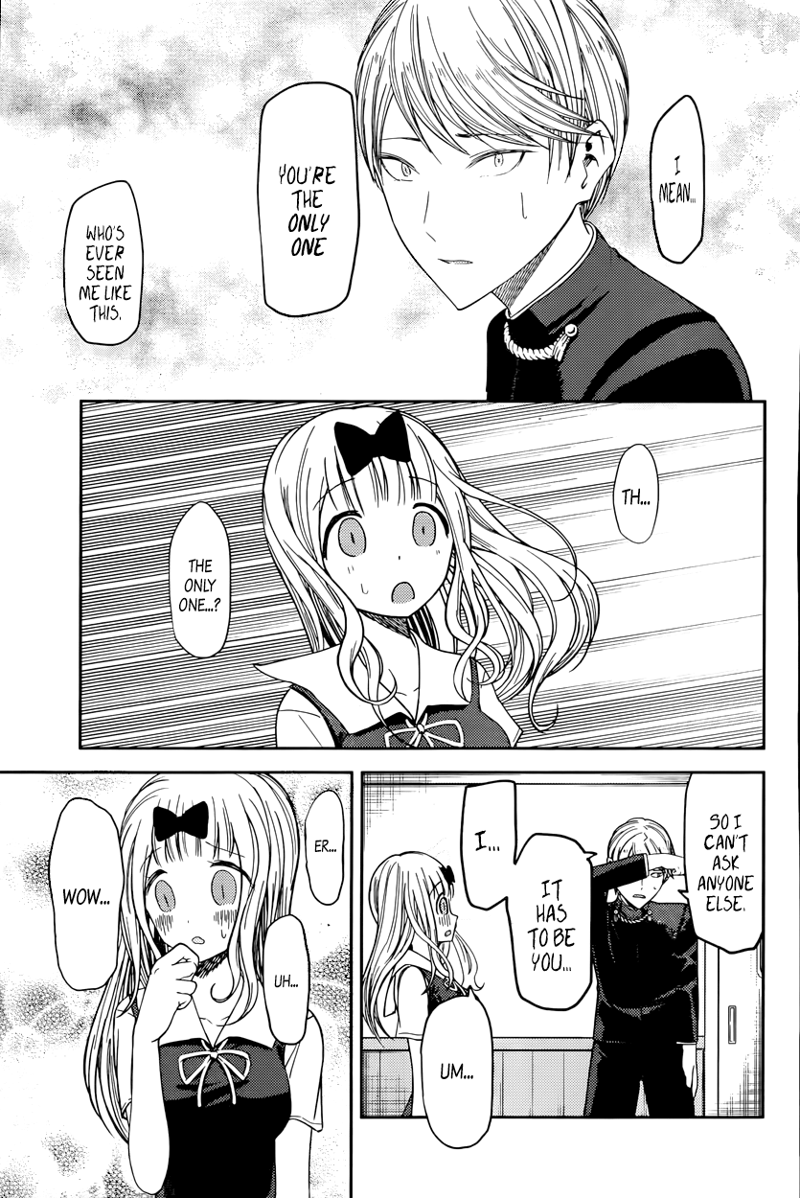

In [1]:
from pathlib import Path
import json
import hashlib
import math
import time
import csv
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display

MODEL_DIR = Path(r'C:\MODELS\PaddleOCR-VL-For-Manga')
PAGE_PATH = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_032cbb4dc8686963\01.png')

# Optional Test B. Set RAW_CACHE=None to test only the full page.
RAW_CACHE = Path(r'C:\Users\ESHAAN\BYTE\Applied-Task\Magi\paddleOCR-Magi\cache_baseline\development\seq_032cbb4dc8686963\magi_raw.json')
PAGE_INDEX = 0  # zero-based index of PAGE_PATH inside RAW_CACHE
MANUAL_BOXES = None  # alternatively: [[x1, y1, x2, y2], ...] in original page pixels

OUTPUT_DIR = Path.cwd() / 'results' / PAGE_PATH.stem
FORCE_OCR = False
RUN_FULL_PAGE = True
RUN_BOX_CROPS = True
MAX_NEW_TOKENS_PAGE = 2048
MAX_NEW_TOKENS_CROP = 256
CROP_PADDING = 4
PROMPT = 'OCR:'

assert PAGE_PATH.is_file(), f'Set PAGE_PATH to a page image: {PAGE_PATH}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with Image.open(PAGE_PATH) as image:
    page = ImageOps.exif_transpose(image).convert('RGB')
page_sha256 = hashlib.sha256(PAGE_PATH.read_bytes()).hexdigest()
print('Page:', PAGE_PATH, '| size:', page.size)
print('Existing results:', [p.name for p in OUTPUT_DIR.glob('*.json')])
display(page.copy().resize((min(800, page.width), round(page.height * min(800, page.width) / page.width))))

## Environment

Use a working PyTorch environment, preferably Python 3.10–3.12. If needed, install
`requirements.txt` into that environment and restart the notebook kernel. The Transformers
path follows the original PaddleOCR-VL custom-code example. PaddlePaddle, DeepSpeed,
and FlashAttention are not required for this experiment.

In [2]:
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoProcessor

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if DEVICE == 'cuda' else torch.float32
print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__)
print('Device:', DEVICE, '| dtype:', DTYPE)
assert (MODEL_DIR / 'config.json').is_file(), f'Download the model into {MODEL_DIR} first'

model = AutoModelForCausalLM.from_pretrained(
    str(MODEL_DIR), trust_remote_code=True, local_files_only=True,
    torch_dtype=DTYPE, attn_implementation='eager',
).to(DEVICE).eval()
model.requires_grad_(False)
processor = AutoProcessor.from_pretrained(str(MODEL_DIR), trust_remote_code=True, local_files_only=True)
print('Loaded:', MODEL_DIR)

`torch_dtype` is deprecated! Use `dtype` instead!


PyTorch: 2.14.0+cu126 | Transformers: 4.57.6
Device: cuda | dtype: torch.bfloat16


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Loaded: C:\MODELS\PaddleOCR-VL-For-Manga


In [3]:
@torch.inference_mode()
def recognize(image, max_new_tokens):
    messages = [{'role': 'user', 'content': [
        {'type': 'image', 'image': image},
        {'type': 'text', 'text': PROMPT},
    ]}]
    inputs = processor.apply_chat_template(messages, tokenize=True,
        add_generation_prompt=True, return_dict=True, return_tensors='pt')
    inputs = {k: v.to(device=DEVICE, dtype=DTYPE if v.is_floating_point() else v.dtype)
              if torch.is_tensor(v) else v for k, v in inputs.items()}
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    started = time.perf_counter()
    output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    generated = output[:, inputs['input_ids'].shape[1]:]
    text = processor.batch_decode(generated, skip_special_tokens=True,
                                  clean_up_tokenization_spaces=False)[0]
    return {'text': text, 'seconds': elapsed, 'generated_tokens': generated.shape[1],
            'hit_token_limit': generated.shape[1] >= max_new_tokens}

def run_cached(image, cache_path, max_new_tokens, crop_bbox=None):
    settings = {'page_sha256': page_sha256, 'model_dir': str(MODEL_DIR),
        'model_config_sha256': hashlib.sha256((MODEL_DIR / 'config.json').read_bytes()).hexdigest(),
        'prompt': PROMPT, 'max_new_tokens': max_new_tokens, 'crop_bbox': crop_bbox,
        'device': DEVICE, 'dtype': str(DTYPE)}
    if cache_path.exists() and not FORCE_OCR:
        saved = json.loads(cache_path.read_text(encoding='utf-8'))
        if saved['settings'] == settings:
            print('Reuse:', cache_path.name)
            return saved
    saved = {'settings': settings, **recognize(image, max_new_tokens)}
    cache_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False), encoding='utf-8')
    return saved

## Test A — entire page

This tests what the recognizer produces from a full page. It does not detect or export text
bounding boxes. Inspect omissions, repetitions, and order against the displayed page.

In [4]:
if RUN_FULL_PAGE:
    full_page = run_cached(page, OUTPUT_DIR / 'full_page.json', MAX_NEW_TOKENS_PAGE)
    print(full_page['text'])
    print('\nGeneration seconds:', round(full_page['seconds'], 2), '| token limit reached:', full_page['hit_token_limit'])
    (OUTPUT_DIR / 'full_page.txt').write_text(full_page['text'], encoding='utf-8')

OutOfMemoryError: CUDA out of memory. Tried to allocate 1.74 GiB. GPU 0 has a total capacity of 8.00 GiB of which 2.35 GiB is free. Process 5280 has 17179869184.00 GiB memory in use. Process 15904 has 17179869184.00 GiB memory in use. Process 15972 has 17179869184.00 GiB memory in use. Process 32912 has 17179869184.00 GiB memory in use. Process 10996 has 17179869184.00 GiB memory in use. Process 2216 has 17179869184.00 GiB memory in use. Process 240 has 17179869184.00 GiB memory in use. Process 21996 has 17179869184.00 GiB memory in use. Process 14380 has 17179869184.00 GiB memory in use. Process 5944 has 17179869184.00 GiB memory in use. Process 24448 has 17179869184.00 GiB memory in use. Process 22392 has 17179869184.00 GiB memory in use. Process 25196 has 17179869184.00 GiB memory in use. Process 18384 has 17179869184.00 GiB memory in use. Process 31288 has 17179869184.00 GiB memory in use. Process 43688 has 17179869184.00 GiB memory in use. Process 30448 has 17179869184.00 GiB memo

## Test B — recognize existing text-box crops

Uses all cached Magi text boxes without essential-text filtering. These boxes come from Magi,
not from PaddleOCR-VL. Existing box order is preserved. Cached OCR is shown beside new OCR
for comparison; it is not treated as ground truth. A cached page hash is checked when available.
For another cache layout, adapt the clearly marked keys in the next cell.

In [ ]:
boxes, old_ocr = [], []
if RUN_BOX_CROPS:
    if MANUAL_BOXES is not None:
        boxes = MANUAL_BOXES
        old_ocr = [''] * len(boxes)
    elif RAW_CACHE is not None:
        assert RAW_CACHE.is_file(), f'Set RAW_CACHE=None or choose an existing cache: {RAW_CACHE}'
        saved = json.loads(RAW_CACHE.read_text(encoding='utf-8'))
        # CONFIG: observed Magi cache keys; change for another schema.
        raw_page = saved['data'][PAGE_INDEX]
        boxes, old_ocr = raw_page['texts'], raw_page.get('ocr', [''] * len(raw_page['texts']))
        identity = saved.get('settings', saved.get('signature', {})).get('pages', [])
        if identity:
            assert identity[PAGE_INDEX]['sha256'] == page_sha256, 'PAGE_PATH does not match the selected cached page'
        assert len(boxes) == len(old_ocr)
    else:
        print('No crop boxes configured. Set RAW_CACHE or MANUAL_BOXES to run Test B.')

def crop_bounds(bbox):
    assert len(bbox) == 4 and all(math.isfinite(float(v)) for v in bbox)
    x1, y1, x2, y2 = bbox
    assert x2 > x1 and y2 > y1, f'Invalid xyxy box: {bbox}'
    bounds = [max(0, math.floor(x1-CROP_PADDING)), max(0, math.floor(y1-CROP_PADDING)),
              min(page.width, math.ceil(x2+CROP_PADDING)), min(page.height, math.ceil(y2+CROP_PADDING))]
    assert bounds[2] > bounds[0] and bounds[3] > bounds[1], f'Box outside page: {bbox}'
    return bounds

if boxes:
    overlay = page.copy()
    draw = ImageDraw.Draw(overlay)
    for index, bbox in enumerate(boxes):
        bounds = crop_bounds(bbox)
        draw.rectangle(bounds, outline='red', width=2)
        draw.text((bounds[0], bounds[1]), str(index+1), fill='red')
    overlay.save(OUTPUT_DIR / 'boxes.png')
    display(overlay)
    print('Boxes:', len(boxes))

In [ ]:
rows = []
for index, (bbox, previous) in enumerate(zip(boxes, old_ocr)):
    bounds = crop_bounds(bbox)
    crop = page.crop(bounds)
    result = run_cached(crop, OUTPUT_DIR / f'crop_{index+1:03d}.json', MAX_NEW_TOKENS_CROP, bounds)
    rows.append({'box_id': f'PG{PAGE_INDEX+1}:T{index+1}', 'bbox': bbox, 'crop_bbox': bounds,
                 'previous_ocr': previous, **result})
    display(crop)
    print('Box', index+1, '| Previous:', previous)
    print('New:', result['text'])
    print('Seconds:', round(result['seconds'], 2), '| token limit reached:', result['hit_token_limit'])

if rows:
    (OUTPUT_DIR / 'crop_results.json').write_text(json.dumps(rows, indent=2, ensure_ascii=False), encoding='utf-8')
    (OUTPUT_DIR / 'crop_text.txt').write_text('\n\n'.join(r['text'] for r in rows), encoding='utf-8')
    with (OUTPUT_DIR / 'crop_comparison.csv').open('w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=['box_id', 'bbox', 'previous_ocr', 'new_ocr', 'seconds', 'hit_token_limit'])
        writer.writeheader()
        for row in rows:
            writer.writerow({'box_id': row['box_id'], 'bbox': json.dumps(row['bbox']),
                'previous_ocr': row['previous_ocr'], 'new_ocr': row['text'],
                'seconds': row['seconds'], 'hit_token_limit': row['hit_token_limit']})
print('Saved outputs:', OUTPUT_DIR.resolve())

If token_limit_reached is True, increase that test's token budget and rerun. No text cleanup,
translation, or story-text filtering is applied. Exact accuracy requires human reference text;
agreement with previous OCR is not an accuracy measure. Set FORCE_OCR=True after replacing
model weights at the same path, because the cache checks config identity rather than weight contents.

Sources: [manga model](https://huggingface.co/jzhang533/PaddleOCR-VL-For-Manga),
[original Transformers inference example](https://huggingface.co/PaddlePaddle/PaddleOCR-VL#paddleocr-vl-09b-usage-with-transformers).